# Gemini Flash Introduction

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Gemini_Flash_Introduction.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
</table>

## Installing the latest version of the Gemini SDK

In [46]:
!pip install -q -U google-genai # Install the Python SDK

## Import the Gemini python SDK

In [57]:
from google import genai

## Set up your API key

To run the following cell, your API key must be stored it in a Colab Secret named `GOOGLE_API_KEY`. If you don't already have an API key, or you're not sure how to create a Colab Secret, see the [Authentication](https://github.com/google-gemini/cookbook/blob/main/quickstarts/Authentication.ipynb) quickstart for an example.

In [60]:
from google.colab import userdata

GOOGLE_API_KEY=userdata.get('GOOGLE_API_KEY')
client = genai.Client(api_key=GOOGLE_API_KEY)

## Completing the Setup

Next, we will set up a model version and get ready to make some prompts.

Let's consider the following scenario. You have just been hired as a student tutor at UC Berkeley! You're assigned various tasks across campus, helping a variety of students through their homework. Lets use some of the prompts below to help out the students

First, you are tasked to help Derek create a poem from scratch. This poem should be a free verse about the pasta Linguine.

In [61]:
prompt = """Create a free verse about the pasta Linguine. Make it descriptive
about the shape, taste, and texture of pasta. Make the poem at least five lines
long."""

In [64]:
response = client.models.generate_content(
    model='gemini-3.8-flash',
    contents=prompt
)
print(response.text)

Slender ribbons, flattened tongues of pressed semolina,
swirling through boiling tides to shed their brittle spine.
Neither thin like wire nor broad like heavy planks,
they emerge with an elegant, springy curve,
possessing that firm, toothsome resistance in their core—
supple enough to glide, dense enough to chew.
They carry a quiet, sun-baked sweetness of simple wheat,
clinging greedily to the slick gold of olive oil and briny sea,
slipping across the tongue in silky, savory weight,
a warm, twirling architecture of pure comfort.


As an aside, we will be using the `genai.upload_file()` method using the File API from Gemini API. This allows users to upload media files, such as images, audio, and video to be used as input for prompting and generating AI responses. This feature integrates media with text-based prompts to enhance the context and relevance of the generated outputs.

Now, you need to help architecture student Diana place pots and pans in the following kitchen without messing up the style of the existing design.

Thus, we need to determine the key items in this kitchen and the color of these items.

Create a prompt that will take in an image of a room in a house and will redecorate that room given the specifications above.

In [65]:
!wget -O kitchen.jpeg "https://video.udacity-data.com/topher/2024/June/667b0908_kitchen/kitchen.jpeg"

image_upload = client.files.upload(file='kitchen.jpeg')

--2026-11-10 15:42:59--  https://video.udacity-data.com/topher/2024/June/667b0908_kitchen/kitchen.jpeg
Resolving video.udacity-data.com (video.udacity-data.com)... 172.64.148.171, 104.18.39.85, 2a06:98c1:3100::6812:2755, ...
Connecting to video.udacity-data.com (video.udacity-data.com)|172.64.148.171|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1093598 (1.0M) [image/jpeg]
Saving to: ‘kitchen.jpeg’

kitchen.jpeg        100%[===================>]   1.04M  --.-KB/s    in 0.05s   

2026-11-10 15:42:59 (21.8 MB/s) - ‘kitchen.jpeg’ saved [1093598/1093598]



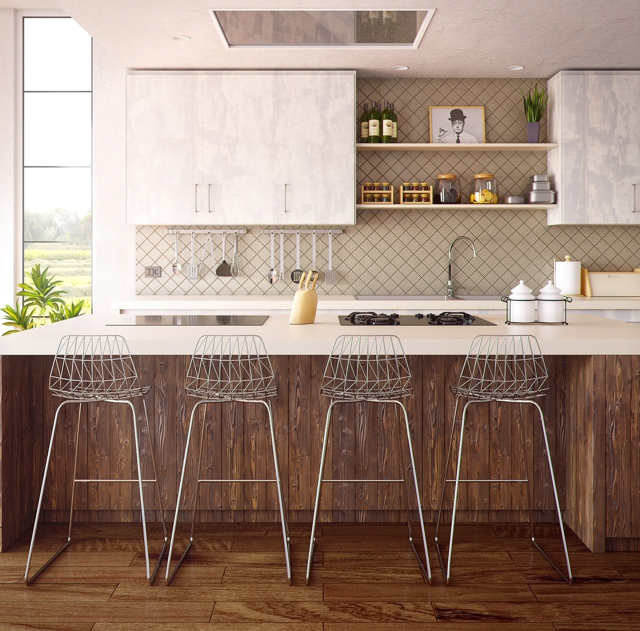

In [66]:
from PIL import Image
image = Image.open('kitchen.jpeg')
resized_image = image.resize((int(image.size[0] / 2), int(image.size[1] / 2)))

resized_image

In [67]:
prompt = """This image contains a a kitchen with a seating area (four chairs),
cabinets, stove, a large window, and a knife holder. Give a description of the
following room, including the key components and each of the colors (be specific
about what exact shade) of the items. Explain in what location we could place 5
pots and pans so that the kitchen retains its minimalistic appeal and clutter
doesn't increase substantially."""

In [73]:
response = client.models.generate_content(
    model='gemini-3.8-flash',
    contents=[image_upload, "Describe this image"]
)
print(response.text)

A straight-on, eye-level photograph captures a bright, modern kitchen featuring a blend of rustic wooden accents and contemporary minimalist design.

### **Foreground & Kitchen Island**
* **Bar Stools:** Four identical wireframe bar stools with polished chrome finishes are lined up evenly in front of the island. They feature geometric mesh bucket seats and sled-style leg bases with integrated footrests.
* **Island Structure:** The base of the island is clad in rich, dark-stained vertical wood planks displaying prominent grain textures. It is topped with a thick, smooth, off-white countertop.
* **Island Countertop Elements:** 
  * On the left sits a flush, black induction or ceramic cooktop.
  * In the center is a pale, curved wooden knife block filled with knives.
  * To the right of the knife block is a built-in black gas cooktop with multiple burners.
  * On the far right edge rests a black wire caddy holding two white ceramic canisters with pointed lids.
* **Flooring:** The island s

Now, Harbani, a student in a film class needs your help with understanding a piece of audio given to her.

Help decide what the audio file is comprised of and what kind of mood it sets.

In [70]:
!wget -O summer-rainampthunder-162009.mp3 "https://video.udacity-data.com/topher/2024/June/667b09e0_summer-rain-thunder/summer-rain-thunder.mp3"

audio_upload = client.files.upload(file='summer-rainampthunder-162009.mp3')

--2026-11-10 15:43:53--  https://video.udacity-data.com/topher/2024/June/667b09e0_summer-rain-thunder/summer-rain-thunder.mp3
Resolving video.udacity-data.com (video.udacity-data.com)... 172.64.148.171, 104.18.39.85, 2a06:98c1:3103::ac40:94ab, ...
Connecting to video.udacity-data.com (video.udacity-data.com)|172.64.148.171|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3889152 (3.7M) [audio/mpeg]
Saving to: ‘summer-rainampthunder-162009.mp3’

summer-rainampthund 100%[===================>]   3.71M  --.-KB/s    in 0.07s   

2026-11-10 15:43:53 (50.6 MB/s) - ‘summer-rainampthunder-162009.mp3’ saved [3889152/3889152]



In [71]:
from IPython.display import Audio

Audio("summer-rainampthunder-162009.mp3")

In [74]:
prompt = """Listen carefully to the following audio file, what's in it? What
mood does it set and what kind of film could it be used in?"""

response = client.models.generate_content(
    model='gemini-3.8-flash',
    contents=[prompt, audio_upload]
)
print(response.text)

### 1. What's in the audio?
The audio consists of the natural ambiance of a heavy thunderstorm. It features the steady, continuous downpour of rain, accompanied by deep, resonant rolls and rumbles of thunder occurring at various distances.

---

### 2. What mood does it set?
* **Ominous and Tense:** The low, reverberating thunder conveys anticipation, danger, or impending conflict.
* **Melancholic and Gloomy:** The relentless downpour creates a somber, brooding, or reflective atmosphere.
* **Isolation:** It evokes a feeling of being trapped indoors or stranded alone in harsh weather.

---

### 3. What kind of film could it be used in?
* **Horror / Psychological Thriller:** Ideal for establishing the classic "dark and stormy night" trope, building suspense before a scare or isolating characters in a remote house.
* **Film Noir / Neo-Noir / Detective Mystery:** Perfect for an atmospheric backdrop as a detective works late in an office, drives through a neon-lit, rain-soaked city, or inve

Finally, Vanessa on the Tennis team needs your help understanding why she has lost her last few matches. Her coach has told her that she is struggling to place the ball in the correct place.

Break down the following tennis film and summarize what each player does and where the ball lands. Explain how the winning player uses placement to win the point.

In [76]:
!wget -O tennis.mp4 "https://video.udacity-data.com/topher/2024/June/667b096b_tennis/tennis.mp4"

video_upload = client.files.upload(file='tennis.mp4')

--2026-11-10 15:45:05--  https://video.udacity-data.com/topher/2024/June/667b096b_tennis/tennis.mp4
Resolving video.udacity-data.com (video.udacity-data.com)... 172.64.148.171, 104.18.39.85, 2a06:98c1:3100::6812:2755, ...
Connecting to video.udacity-data.com (video.udacity-data.com)|172.64.148.171|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15157892 (14M) [video/mp4]
Saving to: ‘tennis.mp4’

tennis.mp4          100%[===================>]  14.46M  --.-KB/s    in 0.1s    

2026-11-10 15:45:05 (98.9 MB/s) - ‘tennis.mp4’ saved [15157892/15157892]



In [77]:
from IPython.display import Video

Video("tennis.mp4", embed=True, width=540)

In [80]:
prompt = """Describe the video. Describe how each tennis player hits the ball and
describe where the ball lands. Explain how the winning player positions the ball
to land in certain spots to win the point."""

response = client.models.generate_content(
    model='gemini-3.8-flash',
    contents=[prompt, video_upload]
)

print(response.text)

### Video Overview
The video provides an aerial, top-down drone perspective of a clay tennis court where two players are engaged in a dynamic rally from the baseline until one player successfully closes out the point.

---

### Shot-by-Shot Analysis & Ball Trajectory

1. **Left Player’s Opening Shot (0:00 – 0:02):**
   * **The Shot:** Positioned near the bottom baseline (deuce side), the player on the left strikes a solid crosscourt forehand.
   * **Where it lands:** The ball lands deep near the baseline in the upper corner (ad side) of the right player's court.

2. **Right Player’s Return (0:02 – 0:04):**
   * **The Shot:** Moving backward and across, the right player hits a forehand return back across the court.
   * **Where it lands:** The ball bounces at a moderate depth in the lower half (deuce side) of the left player's court.

3. **Left Player’s Aggressive Drive (0:04 – 0:05):**
   * **The Shot:** Stepping into the ball, the left player drives an aggressive, heavy forehand aimed